# Lab 6: Association Rule Mining with Apriori and FP-Growth
**Name:** Minh Le  
**Course:** MSCS 634 — Advanced Big Data and Data Mining  
**Assignment:** Lab 6 — Association Rule Mining

This lab studies shopping baskets using frequent itemsets, association rules, and Seaborn visualizations. Both algorithms receive the same cleaned transaction matrix and thresholds so their results and execution times can be compared fairly.

## 1. Data preparation
The public **Groceries** dataset contains 9,835 point-of-sale transactions collected over 30 days at a grocery outlet, with products aggregated to 169 categories. Each CSV row is one basket; each field is an item category. This preserves the item-level basket structure needed for mining, although it does not include quantities, prices, or customer identifiers.

Sources: [official arules dataset documentation](https://michael.hahsler.net/arules/reference/Groceries.html) and [CSV mirror](https://github.com/MartinThoma/algorithms/blob/427b0a8670f21a82e539594949985d44b8d326c2/arules/groceries.csv). The download is pinned to a commit and verified with SHA-256. No data file is written to the repository.

Dataset reference: Hahsler, M., Hornik, K., & Reutterer, T. (2006). *Implications of probabilistic data modeling for mining association rules*. In *From Data and Information Analysis to Knowledge Engineering*, pp. 598–605, Springer.

Run the following setup cell if dependencies are missing, then restart the kernel and run all cells.

In [1]:
# Uncomment to install into the current notebook kernel:
# %pip install pandas numpy matplotlib seaborn mlxtend ipykernel
import csv
import hashlib
import io
import math
import platform
import sys
from importlib.metadata import version
from time import perf_counter
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13})
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0], '| Platform:', platform.platform())
print({p: version(p) for p in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'mlxtend']})

Python: 3.13.2 | Platform: Windows-11-10.0.26200-SP0
{'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'mlxtend': '0.25.0'}


In [2]:
DATA_URL = 'https://raw.githubusercontent.com/MartinThoma/algorithms/427b0a8670f21a82e539594949985d44b8d326c2/arules/groceries.csv'
EXPECTED_SHA256 = '4a408c397f0c0128330155b419e2a56e1868f719e1b0e205e4aefa49fa668ca6'
with urlopen(DATA_URL, timeout=60) as response:
    raw = response.read()
assert hashlib.sha256(raw).hexdigest() == EXPECTED_SHA256, 'Unexpected dataset content'
rows = list(csv.reader(io.StringIO(raw.decode('utf-8-sig'))))
transactions = []
blank_items = trimmed_items = duplicate_items = empty_baskets = 0
for row in rows:
    blank_items += sum(not item.strip() for item in row)
    trimmed_items += sum(item != item.strip() for item in row)
    items = [item.strip() for item in row if item.strip()]
    duplicate_items += len(items) - len(set(items))
    basket = sorted(set(items))
    if basket:
        transactions.append(basket)
    else:
        empty_baskets += 1
encoder = TransactionEncoder()
basket = pd.DataFrame(encoder.fit(transactions).transform(transactions), columns=encoder.columns_)
assert basket.shape == (9835, 169)
assert basket.dtypes.eq(bool).all() and not basket.isna().any().any()
# Identical baskets may be separate purchases: keep their transaction multiplicity.
audit = pd.Series({'Raw baskets': len(rows), 'Retained baskets': len(transactions),
                   'Unique item categories': basket.shape[1], 'Whitespace-trimmed fields': trimmed_items,
                   'Blank fields removed': blank_items, 'Within-basket duplicates removed': duplicate_items,
                   'Empty baskets removed': empty_baskets,
                   'Repeated basket patterns retained': len(transactions)-len(set(map(tuple, transactions)))})
display(audit.to_frame('Count'))
display(pd.DataFrame({'transaction_id': range(1, 6), 'items': transactions[:5]}))
print(f'Matrix density: {basket.to_numpy().mean():.2%}')

,Count
Raw baskets,9835
Retained baskets,9835
Unique item categories,169
Whitespace-trimmed fields,452
Blank fields removed,0
Within-basket duplicates removed,0
Empty baskets removed,0
Repeated basket patterns retained,2824


,transaction_id,items
0,1,"[citrus fruit, margarine, ready soups, semi-finished bread]"
1,2,"[coffee, tropical fruit, yogurt]"
2,3,[whole milk]
3,4,"[cream cheese, meat spreads, pip fruit, yogurt]"
4,5,"[condensed milk, long life bakery product, other vegetables, whole milk]"


Matrix density: 2.61%


Cleaning trims surrounding whitespace, drops blank fields and empty baskets, and removes repeated items **within** a basket because support counts presence rather than quantity. Identical baskets across different rows are retained because they can represent distinct purchases. A Boolean one-hot matrix represents item presence; zeros mean absence, not missing values.

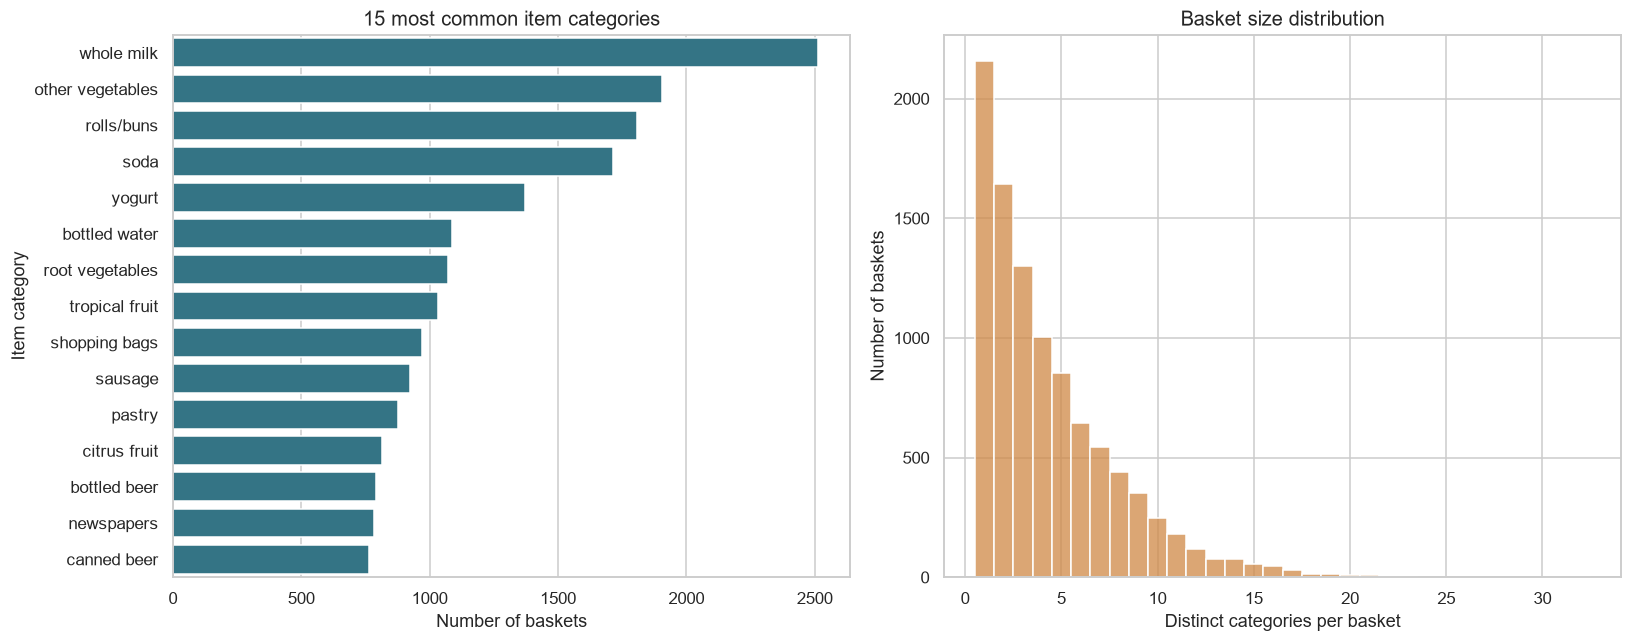

,Basket size
count,9835.000000
mean,4.409456
std,3.589385
min,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,32.000000


Most frequent item: whole milk (2,513 baskets; 25.55%).


In [3]:
item_counts = basket.sum().sort_values(ascending=False)
basket_sizes = basket.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=item_counts.head(15).values, y=item_counts.head(15).index, color='#267c93', ax=axes[0])
axes[0].set(title='15 most common item categories', xlabel='Number of baskets', ylabel='Item category')
sns.histplot(basket_sizes, discrete=True, color='#cf8846', ax=axes[1])
axes[1].set(title='Basket size distribution', xlabel='Distinct categories per basket', ylabel='Number of baskets')
plt.tight_layout(); plt.show()
display(basket_sizes.describe().to_frame('Basket size'))
print(f'Most frequent item: {item_counts.index[0]} ({item_counts.iloc[0]:,} baskets; {item_counts.iloc[0]/len(basket):.2%}).')

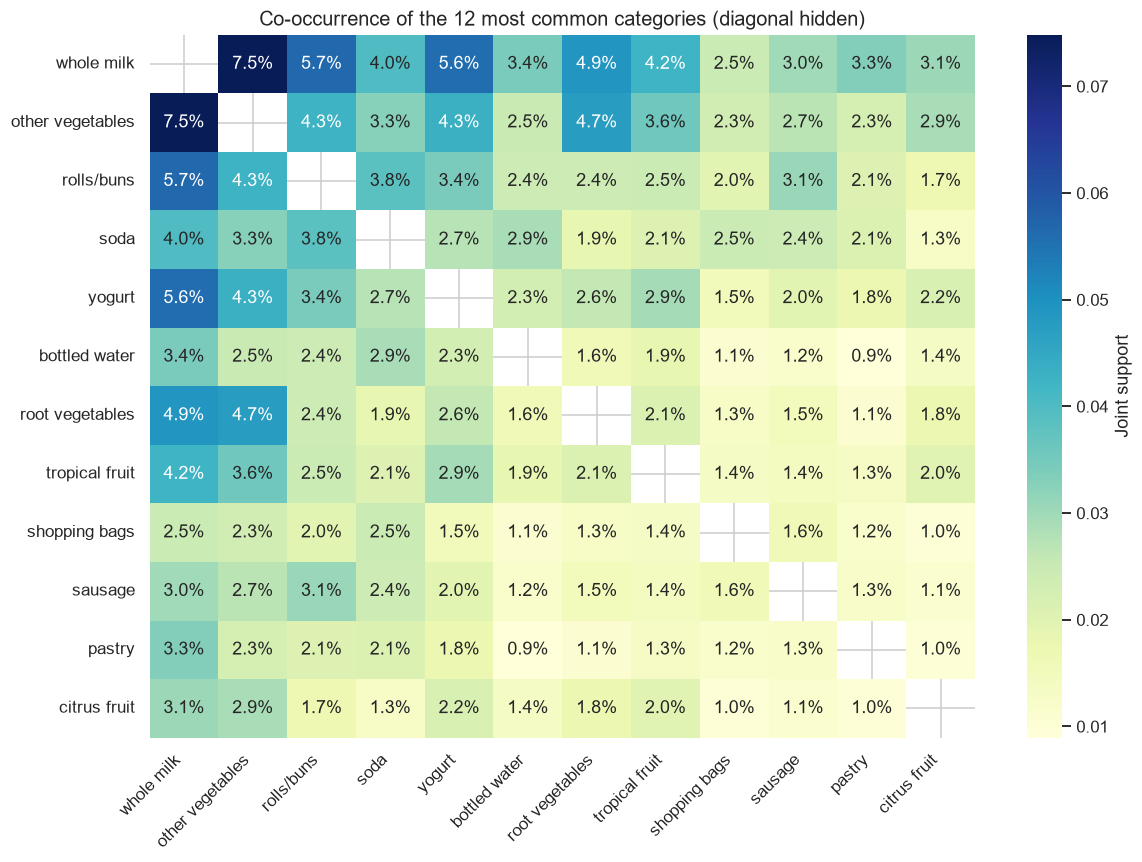

In [4]:
top_items = item_counts.head(12).index
# Convert Boolean values to integers before matrix multiplication to count baskets.
x = basket[top_items].astype('int64')
cooccurrence = (x.T @ x) / len(basket)
plt.figure(figsize=(11, 8))
sns.heatmap(cooccurrence, mask=np.eye(len(top_items), dtype=bool), annot=True,
            fmt='.1%', cmap='YlGnBu', cbar_kws={'label': 'Joint support'})
plt.title('Co-occurrence of the 12 most common categories (diagonal hidden)')
plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

The barplot describes popularity and the histogram shows basket size. The heatmap measures joint support: the fraction of all baskets containing both categories. Popular items can have high joint support without a strong association; lift later adjusts for the consequent's baseline popularity.

## 2. Frequent itemsets using Apriori
A minimum support of **1%** requires an itemset to occur in at least 99 of the 9,835 baskets. This keeps recurring patterns while avoiding very rare combinations. No maximum itemset size or item-category filter is applied. Lower thresholds can reveal more patterns but increase computation and the risk of unstable rules.

Apriori constructs candidate itemsets level by level and prunes candidates whose subsets are not frequent.

Minimum basket count: 99
Apriori frequent itemsets: 333


**All Apriori frequent itemsets:**

itemset,size,support
whole milk,1,0.25552
other vegetables,1,0.19349
rolls/buns,1,0.18393
soda,1,0.17438
yogurt,1,0.13950
bottled water,1,0.11052
root vegetables,1,0.10900
tropical fruit,1,0.10493
shopping bags,1,0.09853
sausage,1,0.09395


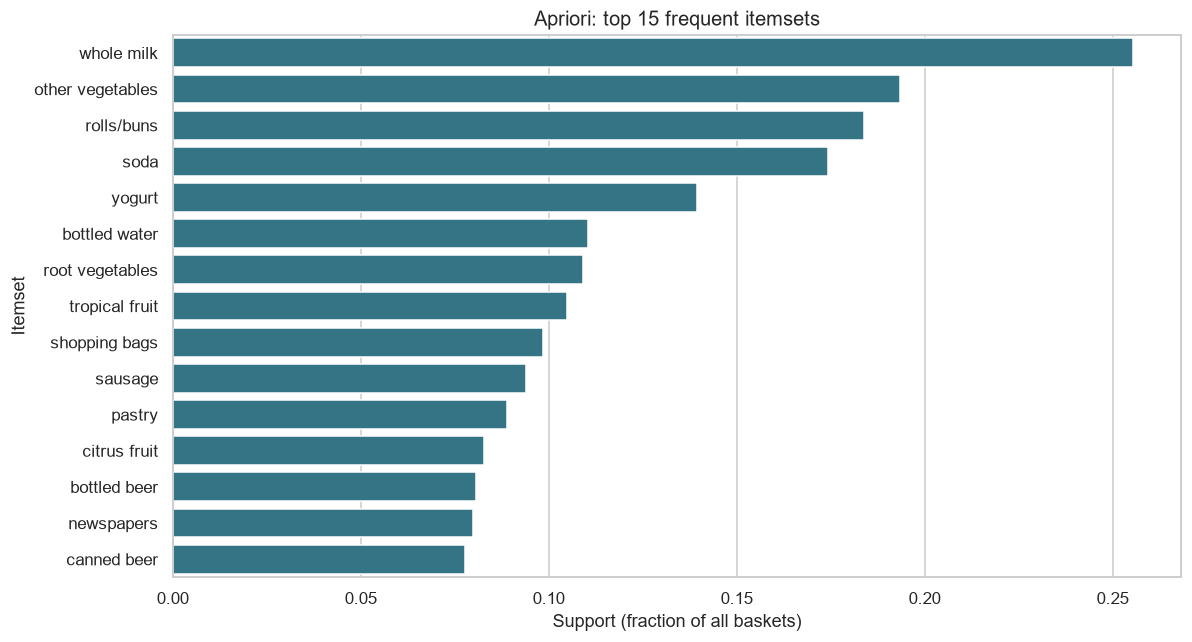

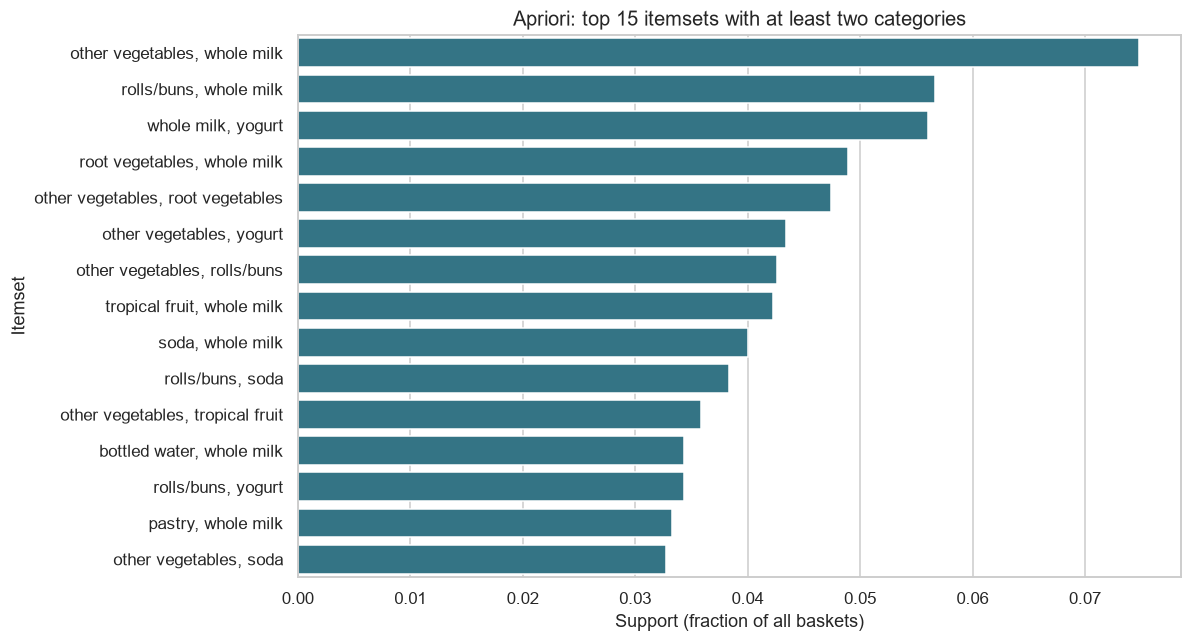

In [5]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.50
print('Minimum basket count:', math.ceil(MIN_SUPPORT * len(basket)))
apriori_sets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
def itemset_table(frame):
    result = frame.assign(itemset=frame['itemsets'].map(lambda s: ', '.join(sorted(s))),
                          size=frame['itemsets'].map(len))
    return result[['itemset', 'size', 'support']].sort_values(['support', 'itemset'], ascending=[False, True]).reset_index(drop=True)
def plot_itemsets(frame, title):
    top = itemset_table(frame).head(15)
    plt.figure(figsize=(11, 6))
    sns.barplot(data=top, x='support', y='itemset', color='#267c93')
    plt.title(title); plt.xlabel('Support (fraction of all baskets)'); plt.ylabel('Itemset')
    plt.tight_layout(); plt.show()
print('Apriori frequent itemsets:', len(apriori_sets))
# Display every frequent itemset and its support in a scrollable HTML table.
display(Markdown('**All Apriori frequent itemsets:**'))
from IPython.display import HTML
display(HTML('<div style="max-height:400px;overflow:auto">'+itemset_table(apriori_sets).to_html(index=False, float_format=lambda x:f'{x:.5f}')+'</div>'))
plot_itemsets(apriori_sets, 'Apriori: top 15 frequent itemsets')
plot_itemsets(apriori_sets[apriori_sets.itemsets.map(len) >= 2], 'Apriori: top 15 itemsets with at least two categories')

## 3. Frequent itemsets using FP-Growth
FP-Growth compresses transactions into an FP-tree and mines conditional patterns, avoiding Apriori's explicit candidate generation. It uses the same support threshold, input matrix, and unrestricted itemset size.

FP-Growth frequent itemsets: 333


itemset,size,support
whole milk,1,0.25552
other vegetables,1,0.19349
rolls/buns,1,0.18393
soda,1,0.17438
yogurt,1,0.13950
bottled water,1,0.11052
root vegetables,1,0.10900
tropical fruit,1,0.10493
shopping bags,1,0.09853
sausage,1,0.09395


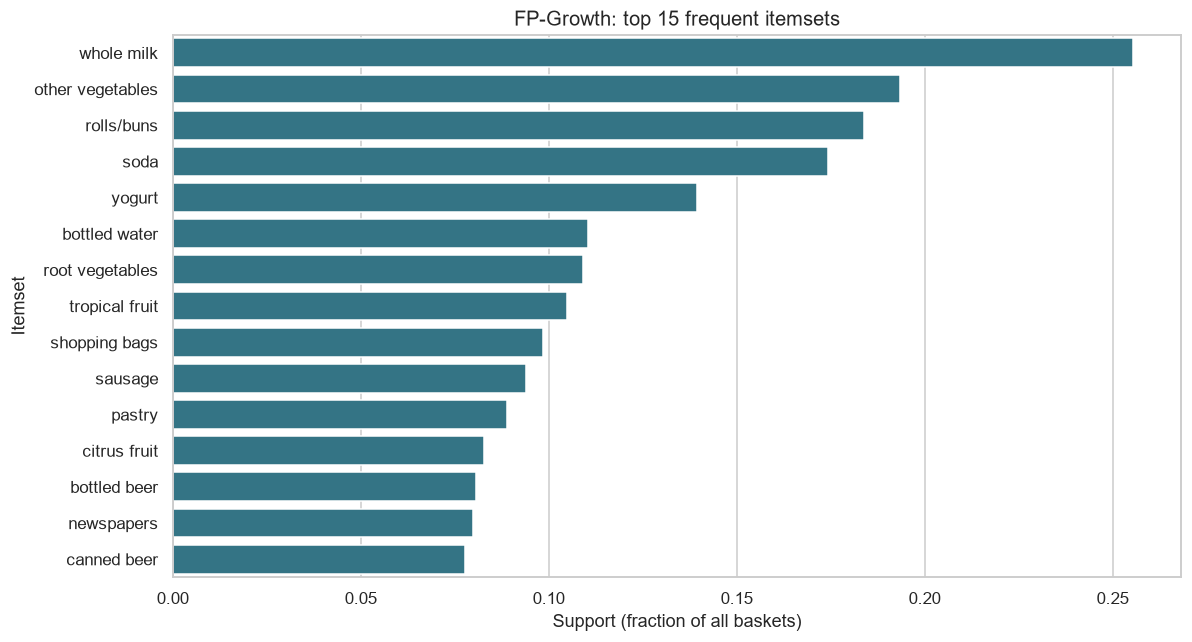

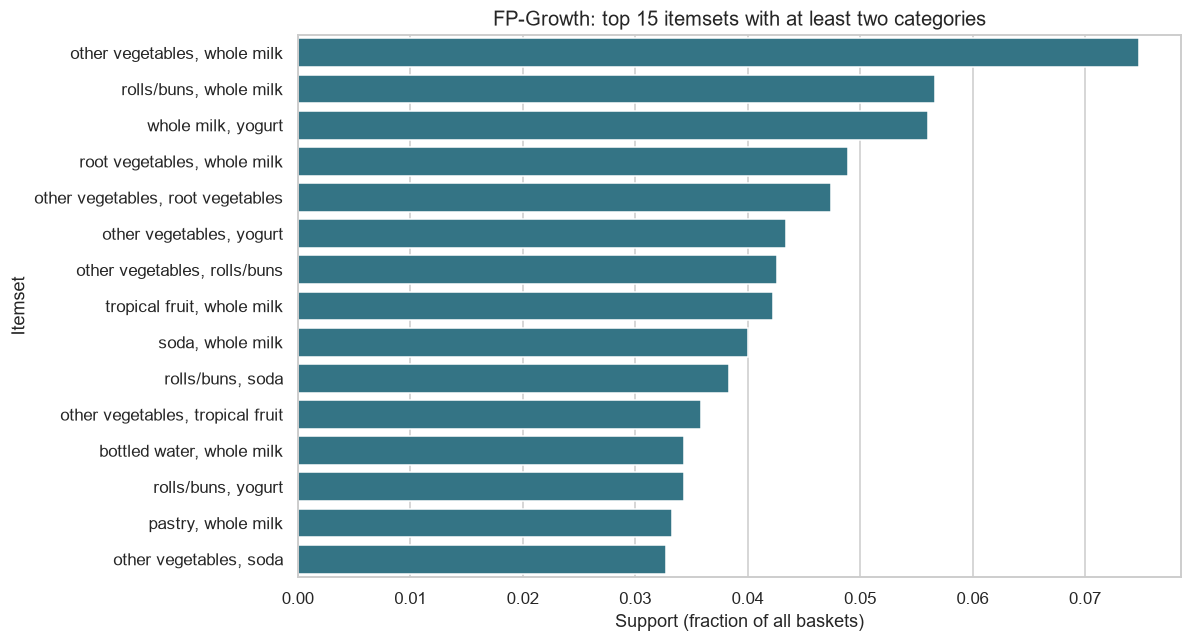

Verified: identical itemsets and support values.


In [6]:
fp_sets = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
print('FP-Growth frequent itemsets:', len(fp_sets))
display(HTML('<div style="max-height:400px;overflow:auto">'+itemset_table(fp_sets).to_html(index=False, float_format=lambda x:f'{x:.5f}')+'</div>'))
plot_itemsets(fp_sets, 'FP-Growth: top 15 frequent itemsets')
plot_itemsets(fp_sets[fp_sets.itemsets.map(len) >= 2], 'FP-Growth: top 15 itemsets with at least two categories')
def canonical_sets(frame):
    return frame.assign(key=frame.itemsets.map(lambda s: tuple(sorted(s)))).set_index('key')['support'].sort_index()
pd.testing.assert_series_equal(canonical_sets(apriori_sets), canonical_sets(fp_sets))
print('Verified: identical itemsets and support values.')

### Timing comparison
Time only the mining call, excluding download, cleaning, plotting, and rule generation. Warm up each implementation, then alternate execution order over seven repeats to reduce order effects. Report the median and interquartile range. These are local implementation measurements, not universal algorithm rankings.

,median,q1,q3,minimum,maximum
algorithm,,,,,
Apriori,0.085742,0.084751,0.090077,0.081894,0.092736
FP-Growth,0.098221,0.094558,0.152228,0.092978,0.266945


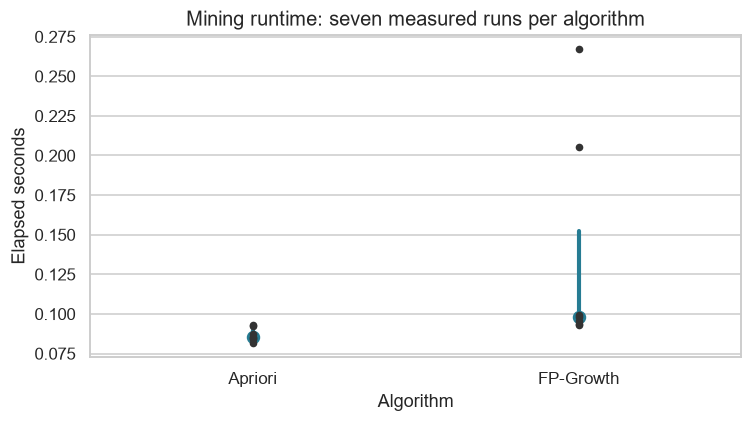

In [7]:
algorithms = {'Apriori': apriori, 'FP-Growth': fpgrowth}
for algorithm in algorithms.values():
    algorithm(basket, min_support=MIN_SUPPORT, use_colnames=True)
timings = []
for repeat in range(7):
    names = list(algorithms) if repeat % 2 == 0 else list(reversed(algorithms))
    for name in names:
        start = perf_counter()
        algorithms[name](basket, min_support=MIN_SUPPORT, use_colnames=True)
        timings.append({'algorithm': name, 'repeat': repeat+1, 'seconds': perf_counter()-start})
timing_df = pd.DataFrame(timings)
timing_summary = timing_df.groupby('algorithm')['seconds'].agg(
    median='median', q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75), minimum='min', maximum='max')
display(timing_summary)
plt.figure(figsize=(7, 4))
sns.pointplot(data=timing_df, x='algorithm', y='seconds', estimator=np.median, errorbar=('pi', 50), color='#267c93', linestyle='none')
sns.stripplot(data=timing_df, x='algorithm', y='seconds', color='#333333', jitter=False)
plt.title('Mining runtime: seven measured runs per algorithm')
plt.xlabel('Algorithm'); plt.ylabel('Elapsed seconds'); plt.tight_layout(); plt.show()

## 4. Generating and analyzing association rules
Generate rules independently from each algorithm's frequent itemsets with **confidence ≥ 50%**. For a rule A → B:

- **Support:** P(A ∪ B), the fraction of all baskets containing both sides.
- **Confidence:** P(B | A), the fraction of baskets with A that also contain B.
- **Lift:** P(B | A) / P(B). Lift above 1 indicates positive association relative to B's baseline prevalence.

High confidence alone can reflect a popular consequent. Rank positive-association rules by lift, then confidence and support. These are descriptive associations, not evidence of causation or validated recommendations.

In [8]:
rules_apriori = association_rules(apriori_sets, metric='confidence', min_threshold=MIN_CONFIDENCE)
rules_fp = association_rules(fp_sets, metric='confidence', min_threshold=MIN_CONFIDENCE)
def canonical_rules(frame):
    return frame.assign(key=frame.apply(lambda r:(tuple(sorted(r.antecedents)), tuple(sorted(r.consequents))), axis=1)).set_index('key')[['support', 'confidence', 'lift']].sort_index()
pd.testing.assert_frame_equal(canonical_rules(rules_apriori), canonical_rules(rules_fp))
def rules_table(frame):
    result = frame.copy()
    for col in ['antecedents', 'consequents']:
        result[col] = result[col].map(lambda s: ', '.join(sorted(s)))
    return result[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(
        ['lift', 'confidence', 'support', 'antecedents', 'consequents'], ascending=[False, False, False, True, True]).reset_index(drop=True)
for name, rules in [('Apriori', rules_apriori), ('FP-Growth', rules_fp)]:
    print(f'{name}: {len(rules)} rules')
    display(rules_table(rules).head(15))
print('Verified: identical rule identities, support, confidence, and lift.')
strong_rules = rules_table(rules_apriori[rules_apriori.lift > 1])
assert len(strong_rules) >= 3

Apriori: 15 rules


,antecedents,consequents,support,confidence,lift
0,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608
1,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999
2,"rolls/buns, root vegetables",other vegetables,0.012201,0.502092,2.594890
3,"root vegetables, yogurt",other vegetables,0.012913,0.500000,2.584078
4,"curd, yogurt",whole milk,0.010066,0.582353,2.279125
5,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885
6,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969
7,"root vegetables, yogurt",whole milk,0.014540,0.562992,2.203354
8,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336
9,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747


FP-Growth: 15 rules


,antecedents,consequents,support,confidence,lift
0,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608
1,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999
2,"rolls/buns, root vegetables",other vegetables,0.012201,0.502092,2.594890
3,"root vegetables, yogurt",other vegetables,0.012913,0.500000,2.584078
4,"curd, yogurt",whole milk,0.010066,0.582353,2.279125
5,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885
6,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969
7,"root vegetables, yogurt",whole milk,0.014540,0.562992,2.203354
8,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336
9,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747


Verified: identical rule identities, support, confidence, and lift.


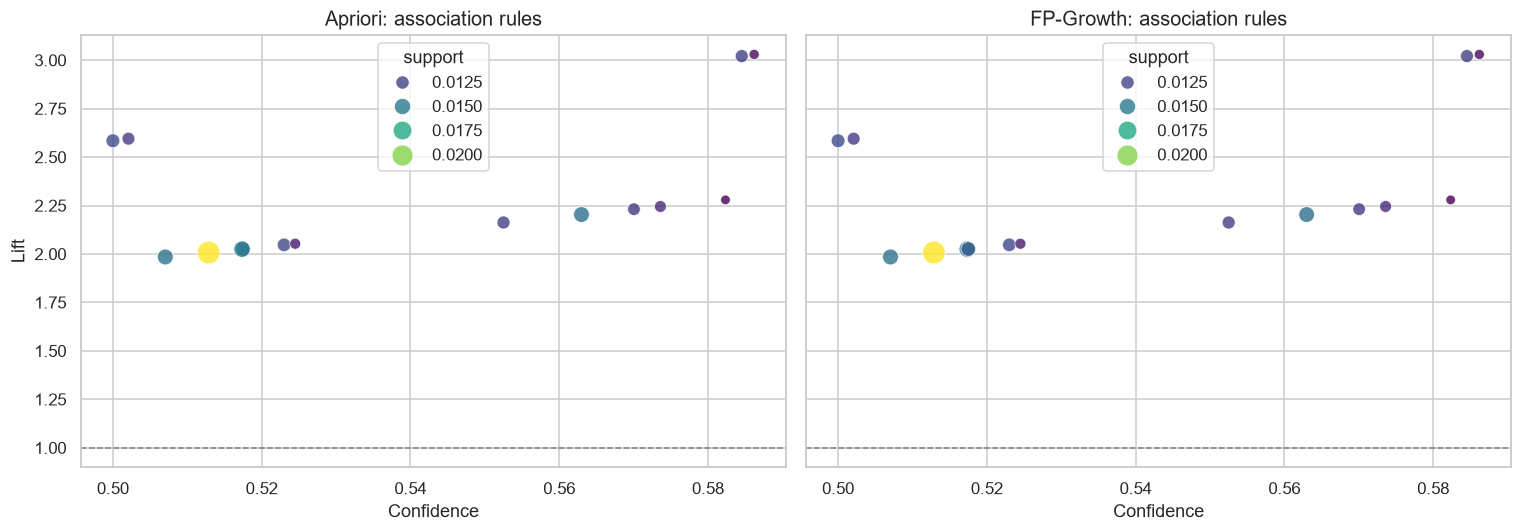

**citrus fruit, root vegetables → other vegetables:** Appears in 102 baskets (support 1.04%). Among baskets containing the antecedent, 58.62% contain the consequent, compared with its baseline frequency of 19.35%. Lift 3.03 means the consequent is 3.03 times as prevalent in these baskets as in all baskets.

**root vegetables, tropical fruit → other vegetables:** Appears in 121 baskets (support 1.23%). Among baskets containing the antecedent, 58.45% contain the consequent, compared with its baseline frequency of 19.35%. Lift 3.02 means the consequent is 3.02 times as prevalent in these baskets as in all baskets.

**rolls/buns, root vegetables → other vegetables:** Appears in 120 baskets (support 1.22%). Among baskets containing the antecedent, 50.21% contain the consequent, compared with its baseline frequency of 19.35%. Lift 2.59 means the consequent is 2.59 times as prevalent in these baskets as in all baskets.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, (name, rules) in zip(axes, [('Apriori', rules_apriori), ('FP-Growth', rules_fp)]):
    sns.scatterplot(data=rules, x='confidence', y='lift', size='support', hue='support',
                    palette='viridis', sizes=(40, 220), alpha=.8, ax=ax)
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)
    ax.set(title=f'{name}: association rules', xlabel='Confidence', ylabel='Lift')
plt.tight_layout(); plt.show()
for _, r in strong_rules.head(3).iterrows():
    count = round(r.support * len(basket))
    baseline = r.confidence / r.lift
    display(Markdown(f"**{r.antecedents} → {r.consequents}:** Appears in {count} baskets "
                     f"(support {r.support:.2%}). Among baskets containing the antecedent, "
                     f"{r.confidence:.2%} contain the consequent, compared with its baseline frequency "
                     f"of {baseline:.2%}. Lift {r.lift:.2f} means the consequent is "
                     f"{r.lift:.2f} times as prevalent in these baskets as in all baskets."))

These rules suggest combinations to investigate for store layout or basket-based recommendations. A useful recommendation should exclude products already in the basket. The rules may overlap and describe the same underlying shopping habits; they should not be treated as independent discoveries. A future evaluation should use new transactions and test incremental sales or recommendation quality before deployment.

## 5. Comparative analysis and challenges

In [10]:
comparison = pd.DataFrame({'Algorithm': ['Apriori', 'FP-Growth'],
                           'Frequent itemsets': [len(apriori_sets), len(fp_sets)],
                           'Rules at confidence >= 0.50': [len(rules_apriori), len(rules_fp)],
                           'Median mining seconds': [timing_summary.loc[n, 'median'] for n in ['Apriori', 'FP-Growth']]})
display(comparison)
faster = timing_summary['median'].idxmin()
slower = timing_summary['median'].idxmax()
ratio = timing_summary.loc[slower, 'median'] / timing_summary.loc[faster, 'median']
reason = ('On this small, sparse matrix, Apriori can benefit from vectorized counting and a manageable candidate set; '
          'FP-tree construction and traversal overhead may outweigh avoided candidate generation.' if faster == 'Apriori' else
          'FP-Growth can benefit from shared transaction prefixes and avoiding explicit candidate generation; '
          'these savings can offset FP-tree construction and traversal overhead.')
display(Markdown(f'**{faster} was faster in this run:** its median runtime was '
                 f'{timing_summary.loc[faster, "median"]:.4f} seconds versus '
                 f'{timing_summary.loc[slower, "median"]:.4f} seconds for {slower} '
                 f'({ratio:.2f}× ratio). {reason} This is a plausible explanation, not a profiling result; '
                 'hardware, library versions, density, support, and data size can change the ordering.'))

,Algorithm,Frequent itemsets,Rules at confidence >= 0.50,Median mining seconds
0,Apriori,333,15,0.085742
1,FP-Growth,333,15,0.098221


**Apriori was faster in this run:** its median runtime was 0.0857 seconds versus 0.0982 seconds for FP-Growth (1.15× ratio). On this small, sparse matrix, Apriori can benefit from vectorized counting and a manageable candidate set; FP-tree construction and traversal overhead may outweigh avoided candidate generation. This is a plausible explanation, not a profiling result; hardware, library versions, density, support, and data size can change the ordering.

**Results:** Both algorithms produce exactly the same itemsets, support values, and rules at identical thresholds; only their mining strategies and measured runtime differ. The top-itemset plots therefore match, as do the rule scatterplots.

**Challenges and decisions:**

- Variable-length CSV rows are baskets, so a normal rectangular CSV loader would misrepresent the data. Python's CSV reader preserves each row as one transaction.
- Some names include trailing spaces. Trimming prevents artificial categories. Repeated basket patterns remain separate observations.
- Boolean matrix multiplication can fail to produce integer counts; converting to integer before the co-occurrence calculation avoids this error.
- Frequent single items dominate the rankings. Additional plots restricted to itemsets of size ≥ 2 reveal combinations without changing the mining input.
- A 1% support threshold balances recurring patterns against rare combinations; 50% confidence makes the conditional interpretation straightforward. These are exploratory choices, not optimized thresholds.
- Tree-based mining is not guaranteed to be faster on a small dataset. Repeated timings and exact output checks avoid assuming a winner.

**Limitations:** Category-level aggregation hides product variation, and this dataset covers one store over only one month. There are no prices, quantities, timestamps, or customer IDs in this CSV, so revenue, temporal stability, and customer-level effects cannot be assessed. There is no held-out validation; the rules are exploratory. Associations do not establish causation.

**Conclusion:** Apriori and FP-Growth recover matching basket patterns. Support measures reach, confidence describes conditional prevalence, and lift helps distinguish association from simple item popularity. Both statistical strength and practical usefulness should guide which rules receive further testing.